In [1]:
import nested_pandas as npd
import lsdb

from nested_pandas import TensorDtype
from nested_pandas.tensors import TensorExtensionArray
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc


/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Generate Milestone 2 (100k Objects with Images & Spectrum)

In [20]:
# Images from Legacy Survey South
ls_image = lsdb.open_catalog("hf://datasets/hugging-science/mmu_legacysurvey_dr10_south_21",
                            columns=["image", "ra", "dec"],
                           )
# Spectra from DESI
desi_spec = lsdb.open_catalog("hf://datasets/UniverseTBD/mmu_desi_edr_sv3",
                              columns=["spectrum", "ra", "dec"],
                             )

mm_cat = ls_image.crossmatch(desi_spec, suffix_method="overlapping_columns")
mm_cat

+--------+-----------------------------------------------+----------------------------------+
| Column | Left (suffix=_mmu_legacysurvey_dr10_south_21) | Right (suffix=_mmu_desi_edr_sv3) |
+--------+-----------------------------------------------+----------------------------------+
|  dec   |      dec_mmu_legacysurvey_dr10_south_21       |       dec_mmu_desi_edr_sv3       |
|   ra   |       ra_mmu_legacysurvey_dr10_south_21       |       ra_mmu_desi_edr_sv3        |
+--------+-----------------------------------------------+----------------------------------+


,image,ra_mmu_legacysurvey_dr10_south_21,dec_mmu_legacysurvey_dr10_south_21,spectrum,ra_mmu_desi_edr_sv3,dec_mmu_desi_edr_sv3,_dist_arcsec
npartitions=579,,,,,,,
"Order: 7, Pixel: 41472","nested<band: [string], flux: [list<element: li...",double[pyarrow],double[pyarrow],"nested<flux: [float], ivar: [float], lsf_sigma...",double[pyarrow],double[pyarrow],double[pyarrow]
...,...,...,...,...,...,...,...
"Order: 7, Pixel: 112605",...,...,...,...,...,...,...
"Order: 7, Pixel: 112607",...,...,...,...,...,...,...


### Convert MMU nested image approach to Tensors

In [5]:
BANDS = ("des-g", "des-r", "des-i", "des-z")
IMAGE_SHAPE = (160, 160)
IMAGE_FIELDS = ("flux", "mask", "ivar")
SCALAR_FIELDS = ("psf_fwhm", "scale")

def _image_values(images: pa.Array, shape: tuple[int, int]) -> pa.Array:
    """Flatten list<list<T>> images into their values, checking they all have the given 2-d shape."""
    rows = pc.list_flatten(images)
    if pc.any(pc.not_equal(pc.list_value_length(images), shape[0])).as_py() or pc.any(
        pc.not_equal(pc.list_value_length(rows), shape[1])
    ).as_py():
        raise ValueError(f"Not all images have shape {shape}")
    return pc.list_flatten(rows)

def image_to_tensor_columns(
    nf: npd.NestedFrame,
    column: str = "image",
    bands=BANDS,
    image_shape=IMAGE_SHAPE,
    band_name=lambda band: band.removeprefix("des-"),
    drop: bool = True,
) -> npd.NestedFrame:
    """Replace a nested image column with one tensor column per (field, band).
    For every band in ``bands``, adds ``{column}_{field}_{band}`` tensor
    columns for flux, mask and ivar, and float columns for psf_fwhm and
    scale. Bands not in ``bands`` are ignored. The output columns and dtypes
    depend only on ``bands``, ``image_shape`` and the input schema, never on
    the data, so empty frames (e.g. dask/LSDB meta or empty partitions) give
    the same result schema. Rows that have no entry for a band get a missing
    tensor / NaN.
    """
    struct = nf[column].array.struct_array.combine_chunks()
    n = len(struct)
    flat_bands = pc.list_flatten(struct.field("band"))
    # Which top-level row each flat (per-band) entry belongs to
    parents = pc.list_parent_indices(struct.field("band"))
    new_columns = {}
    for band in bands:
        positions = pc.indices_nonzero(pc.equal(flat_bands, band))
        band_parents = pc.take(parents, positions)
        if len(pc.unique(band_parents)) != len(band_parents):
            raise ValueError(f"Some rows have band {band!r} more than once")
        # For each top-level row, index into this band's entries, or null when the row lacks the band
        take_idx = np.full(n, -1, dtype=np.int64)
        take_idx[band_parents.to_numpy()] = np.arange(len(positions))
        take_idx = pa.array(take_idx, mask=take_idx < 0)
        suffix = band_name(band)
        for field in IMAGE_FIELDS:
            images = pc.take(pc.list_flatten(struct.field(field)), positions)
            values = _image_values(images, image_shape)
            # Element type from the schema, so it is known even with no data
            dtype = TensorDtype(pa.fixed_shape_tensor(images.type.value_type.value_type, list(image_shape)))
            # Zero-copy: the flat values are already in C order
            band_tensors = pa.FixedSizeListArray.from_arrays(values, dtype.size)
            tensors = pc.take(band_tensors, take_idx)
            new_columns[f"{column}_{field}_{suffix}"] = pd.Series(
                TensorExtensionArray(tensors, dtype=dtype), index=nf.index, copy=False
            )
        for field in SCALAR_FIELDS:
            values = pc.take(pc.take(pc.list_flatten(struct.field(field)), positions), take_idx)
            new_columns[f"{column}_{field}_{suffix}"] = pd.Series(
                values, index=nf.index, dtype=pd.ArrowDtype(values.type)
            )
    out = nf.drop(columns=[column]) if drop else nf.copy()
    return out.assign(**new_columns)


### Apply Tensor Conversion & Write Catalog

In [8]:
# Generate meta lazily (behavioral not computationally)
out = mm_cat.partitions[0].compute()
out.head(0).to_parquet("milestone2_meta.parquet")

In [9]:
npd.read_parquet("milestone2_meta.parquet")

,ra_mmu_legacysurvey_dr10_south_21,dec_mmu_legacysurvey_dr10_south_21,spectrum,ra_mmu_desi_edr_sv3,dec_mmu_desi_edr_sv3,_dist_arcsec,image_flux_g,image_mask_g,image_ivar_g,image_psf_fwhm_g,image_scale_g,image_flux_r,image_mask_r,image_ivar_r,image_psf_fwhm_r,image_scale_r,_healpix_29


In [7]:
from dask.distributed import Client

with Client(n_workers=2, threads_per_worker=1, memory_limit="24GB") as client:
    meta = npd.read_parquet("milestone2_meta.parquet").drop("_healpix_29", axis=1)
    milestone2_cat = mm_cat.map_partitions(image_to_tensor_columns, bands=("des-g", "des-r"), meta=meta)
    milestone2_cat.write_catalog("milestone2", overwrite=True)

/astro/users/brantd/.conda/envs/aion_training/lib/python3.13/site-packages/distributed/node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 38709 instead
  warnings.warn(
Writing Catalog: 100%|██████████| 579/579 [3:30:26<00:00, 21.81s/it]  


In [12]:
m2 = lsdb.open_catalog("milestone2")
m2

,ra_mmu_legacysurvey_dr10_south_21,dec_mmu_legacysurvey_dr10_south_21,spectrum,ra_mmu_desi_edr_sv3,dec_mmu_desi_edr_sv3,_dist_arcsec,image_flux_g,image_mask_g,image_ivar_g,image_psf_fwhm_g,image_scale_g,image_flux_r,image_mask_r,image_ivar_r,image_psf_fwhm_r,image_scale_r
npartitions=548,,,,,,,,,,,,,,,,
"Order: 7, Pixel: 41472",double[pyarrow],double[pyarrow],"nested<flux: [float], ivar: [float], lsf_sigma...",double[pyarrow],double[pyarrow],double[pyarrow],"tensor[float, (160, 160)]","tensor[bool, (160, 160)]","tensor[float, (160, 160)]",float[pyarrow],float[pyarrow],"tensor[float, (160, 160)]","tensor[bool, (160, 160)]","tensor[float, (160, 160)]",float[pyarrow],float[pyarrow]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 7, Pixel: 112605",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 7, Pixel: 112607",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...


In [13]:
len(m2)

172580

Computing Catalog: 100%|██████████| 1/1 [00:00<00:00, 11.44it/s]


ra_mmu_legacysurvey_dr10_south_21  \
_healpix_29                                             
729594401347125473                         196.606908   
729594698490995941                         196.570395   
729594759487585526                         196.598615   
729594842788931257                         196.556864   
729594847830835346                         196.551128   
729594929030447832                         196.554668   
729594952243544768                         196.566502   
729618513321692263                         196.503622   
729618515163565762                         196.499157   
729618553119483519                         196.543293   

                    dec_mmu_legacysurvey_dr10_south_21  ra_mmu_desi_edr_sv3  \
_healpix_29                                                                   
729594401347125473                           24.939503            196.60691   
729594698490995941                            24.92532            196.57039   
729594759487585526                           24.943988           196.598614   
729594842788931257                            24.95042           196.556863   
729594847830835346                           24.949316           196.551126   
729594929030447832                           24.971738           196.554671   
729594952243544768                           24.983864           196.566504   
729618513321692263                           24.996256           196.503623   
729618515163565762                           24.997604           196.499158   
729618553119483519                           25.014328           196.543296   

                    dec_mmu_desi_edr_sv3  _dist_arcsec       image_flux_g  \
_healpix_29                                                                 
729594401347125473             24.939503      0.009472  [160×160] float32   
729594698490995941             24.925322      0.016867  [160×160] float32   
729594759487585526             24.943988      0.001531  [160×160] float32   
729594842788931257             24.950424      0.017383  [160×160] float32   
729594847830835346             24.949317      0.009984  [160×160] float32   
729594929030447832             24.971741      0.014438  [160×160] float32   
729594952243544768              24.98386      0.017552  [160×160] float32   
729618513321692263             24.996256      0.005204  [160×160] float32   
729618515163565762             24.997606      0.008607  [160×160] float32   
729618553119483519             25.014327      0.009156  [160×160] float32   

                      image_mask_g       image_ivar_g  image_psf_fwhm_g  \
_healpix_29                                                               
729594401347125473  [160×160] bool  [160×160] float32          1.659991   
729594698490995941  [160×160] bool  [160×160] float32          1.659991   
729594759487585526  [160×160] bool  [160×160] float32          1.659991   
729594842788931257  [160×160] bool  [160×160] float32          1.584679   
729594847830835346  [160×160] bool  [160×160] float32          1.584679   
729594929030447832  [160×160] bool  [160×160] float32          1.295533   
729594952243544768  [160×160] bool  [160×160] float32          1.489905   
729618513321692263  [160×160] bool  [160×160] float32           1.47417   
729618515163565762  [160×160] bool  [160×160] float32           1.47417   
729618553119483519  [160×160] bool  [160×160] float32          1.489905   

                    image_scale_g       image_flux_r    image_mask_r  \
_healpix_29                                                            
729594401347125473          0.262  [160×160] float32  [160×160] bool   
729594698490995941          0.262  [160×160] float32  [160×160] bool   
729594759487585526          0.262  [160×160] float32  [160×160] bool   
729594842788931257          0.262  [160×160] float32  [160×160] bool   
729594847830835346          0.262  [160×160] float32  [160×160] bool   
729594929030447832          0.262  [160×160] float32  [1
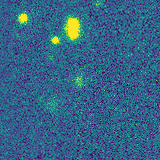
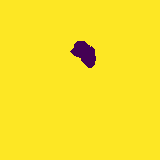
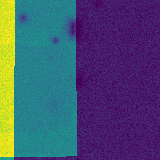
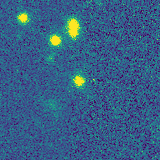
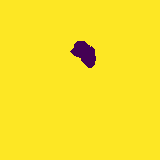
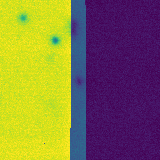
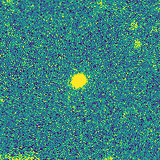
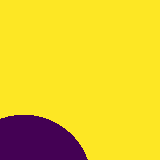
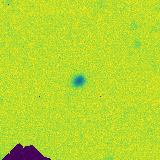
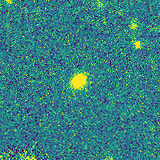
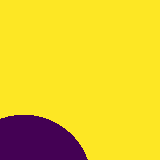
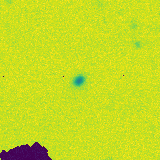
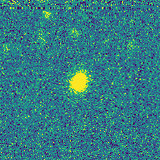
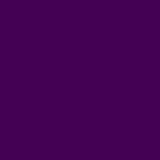
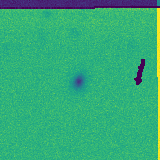
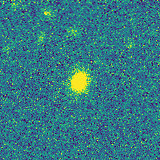
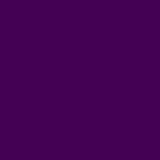
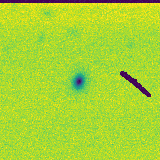
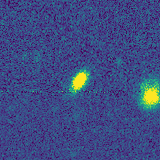
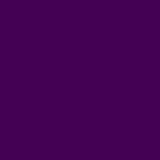
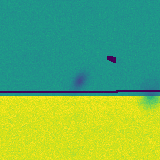
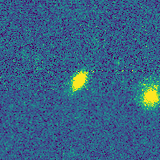
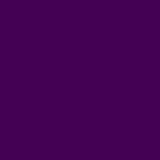
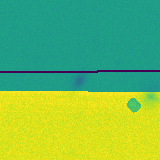
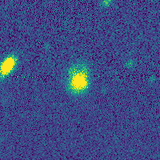
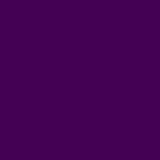
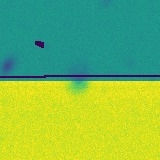
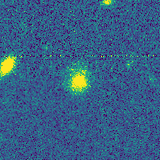
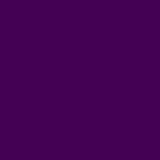
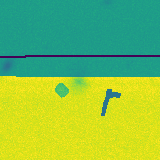
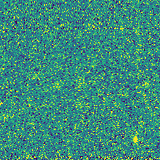
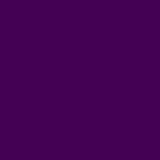
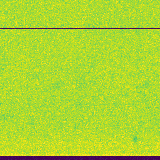
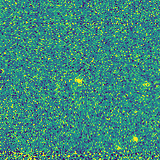
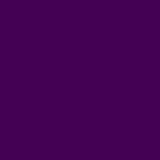
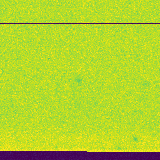
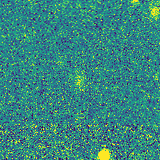
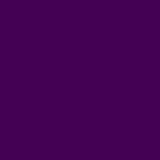
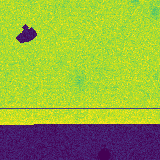
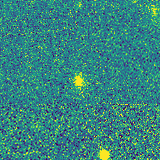
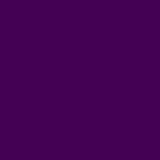
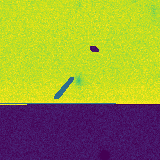
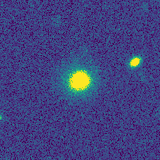
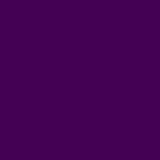
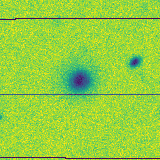
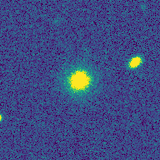
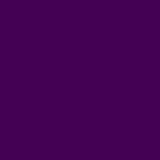
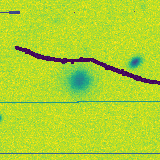
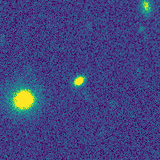
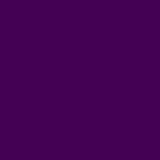
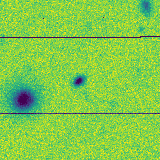
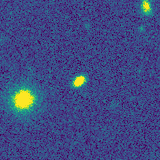
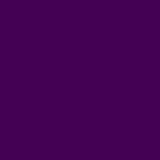
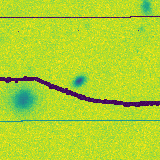
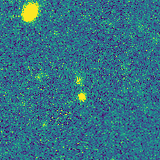
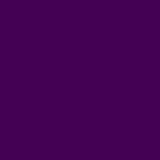
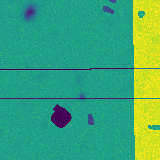
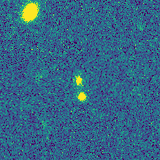
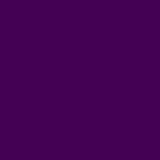
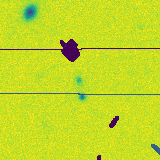

In [14]:
m2.head(10)

In [19]:
m2[["spectrum"]].head(10).info()

Computing Catalog: 100%|██████████| 2/2 [00:00<00:00, 46.18it/s]

<class 'nested_pandas.nestedframe.core.NestedFrame'>
Index: 10 entries, 729594401347125473 to 729618553119483519
Data columns (total 1 columns):
 #   Column    Non-Null Count  Dtype                                                                                  
---  ------    --------------  -----                                                                                  
 0   spectrum  10 non-null     nested<flux: [float], ivar: [float], lsf_sigma: [float], lambda: [float], mask: [bool]>
dtypes: nested<flux: [float], ivar: [float], lsf_sigma: [float], lambda: [float], mask: [bool]>(1)
memory usage: 1.2 MB
